<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 02: Single-factor experiments and ANOVA

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 3.
Problem numbers follow the 8th edition.

## Learning goals

* Fit the one-way fixed-effects model in `statsmodels`, read the ANOVA table and test $H_0: \mu_1 = \dots = \mu_a$.
* Check the model assumptions with residual plots and formal tests (normality, equal variances, independence).
* Compare treatment means after a significant $F$-test: Fisher's LSD, Tukey's HSD and $p$-value adjustments, and understand what each one controls.
* Compute confidence intervals for treatment means and their differences.
* Determine the sample size (replicates per level) needed to detect a given difference with a given power.


## Example from the lecture: plasma etch rate experiment

Lecture 2 analysed the plasma etching experiment (Montgomery, Example 3.1): the etch rate of a wafer at four levels of RF power
(160, 180, 200, 220 W), five replicates per level, 20 runs in random order. We repeat the analysis in Python:
- explore and visualise the raw data,
- fit the one-way ANOVA model (and, for comparison, a model with the run index as a second factor),
- inspect the residuals and test the assumptions,
- compare the treatment means (Fisher's LSD, Tukey's HSD), and
- evaluate the power of the design for several numbers of replicates.

In [1]:
# Core scientific Python stack for the example
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import FTestAnovaPower
from statsmodels.graphics.gofplots import qqplot

sns.set_theme(style="whitegrid")
np.set_printoptions(suppress=True)


In [2]:
# Load the plasma etch rate data used in the lecture example
ETCH_URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/etchrate.txt"
etch_rate = pd.read_csv(ETCH_URL, sep=r"\s+")

# Create categorical views that will be useful for the formulas
etch_rate = etch_rate.assign(
    Power=etch_rate["RF"].astype("category"),
    Run=etch_rate["run"].astype("category")
)

print("Rows, columns:", etch_rate.shape)
display(etch_rate.head())
etch_rate.describe(include="all")


Rows, columns: (20, 5)


,RF,run,rate,Power,Run
0,160,1,575,160,1
1,160,2,542,160,2
2,160,3,530,160,3
3,160,4,539,160,4
4,160,5,570,160,5


,RF,run,rate,Power,Run
count,20.000000,20.000000,20.000000,20.0,20.0
unique,NaN,NaN,NaN,4.0,5.0
top,NaN,NaN,NaN,160.0,1.0
freq,NaN,NaN,NaN,5.0,4.0
mean,190.000000,3.000000,617.750000,NaN,NaN
std,22.941573,1.450953,61.648302,NaN,NaN
min,160.000000,1.000000,530.000000,NaN,NaN
25%,175.000000,2.000000,573.750000,NaN,NaN
50%,190.000000,3.000000,605.000000,NaN,NaN
75%,205.000000,4.000000,659.500000,NaN,NaN


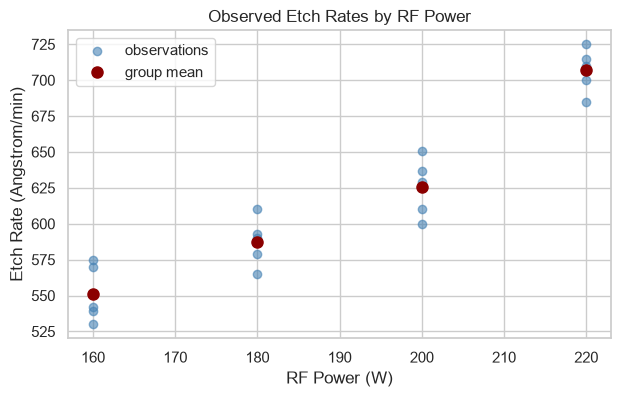

In [3]:
# Visual summary: scatter of observed rates with group means highlighted
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(etch_rate["RF"], etch_rate["rate"], color="steelblue", alpha=0.6, label="observations")
(
    etch_rate.groupby("RF")["rate"].mean()
    .plot(marker="o", color="darkred", linewidth=0, markersize=8, label="group mean", ax=ax)
)
ax.set_xlabel("RF Power (W)")
ax.set_ylabel("Etch Rate (Angstrom/min)")
ax.set_title("Observed Etch Rates by RF Power")
ax.legend()
plt.show()


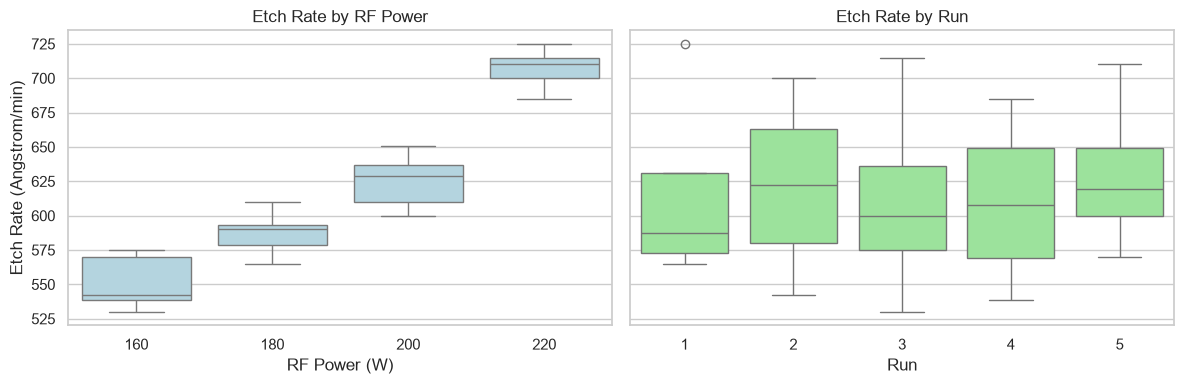

In [4]:
# Boxplots by RF power and by run index (the run index is not a designed block, it only shows that there is no run-to-run drift)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.boxplot(data=etch_rate, x="Power", y="rate", ax=axes[0], color="lightblue")
axes[0].set_title("Etch Rate by RF Power")
axes[0].set_xlabel("RF Power (W)")
axes[0].set_ylabel("Etch Rate (Angstrom/min)")

sns.boxplot(data=etch_rate, x="Run", y="rate", ax=axes[1], color="lightgreen")
axes[1].set_title("Etch Rate by Run")
axes[1].set_xlabel("Run")

plt.tight_layout()
plt.show()


In [5]:
# Fit single-factor and two-factor ANOVA models used in the lecture
model_power = ols("rate ~ C(Power)", data=etch_rate).fit()
model_power_no_intercept = ols("rate ~ C(Power) - 1", data=etch_rate).fit()
model_power_run = ols("rate ~ C(Power) + C(Run)", data=etch_rate).fit()

print(model_power.summary())


                            OLS Regression Results                            
Dep. Variable:                   rate   R-squared:                       0.926
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     66.80
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.88e-09
Time:                        11:58:04   Log-Likelihood:                -84.250
No. Observations:                  20   AIC:                             176.5
Df Residuals:                      16   BIC:                             180.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         551.2000      8.169     

In [6]:
# ANOVA tables (type II sums of squares) for both models
anova_power = sm.stats.anova_lm(model_power, typ=2)
anova_power_run = sm.stats.anova_lm(model_power_run, typ=2)

display(anova_power)
display(anova_power_run)

# Direct comparison of the nested models (Power-only vs Power + Run)
display(sm.stats.anova_lm(model_power, model_power_run))


,sum_sq,df,F,PR(>F)
C(Power),66870.55,3.0,66.797073,2.882866e-09
Residual,5339.20,16.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(Power),66870.55,3.0,62.369063,1.368674e-07
C(Run),1050.50,4.0,0.734838,5.856737e-01
Residual,4288.70,12.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,16.0,5339.2,0.0,NaN,NaN,NaN
1,12.0,4288.7,4.0,1050.5,0.734838,0.585674


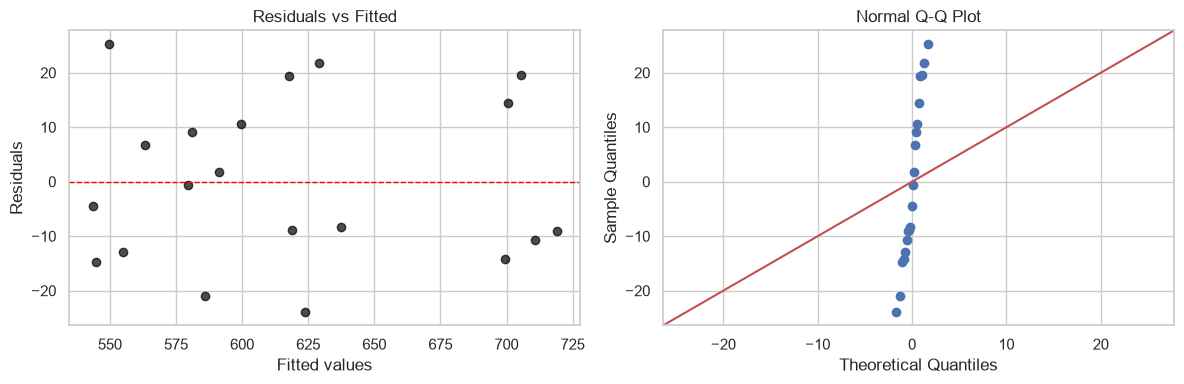

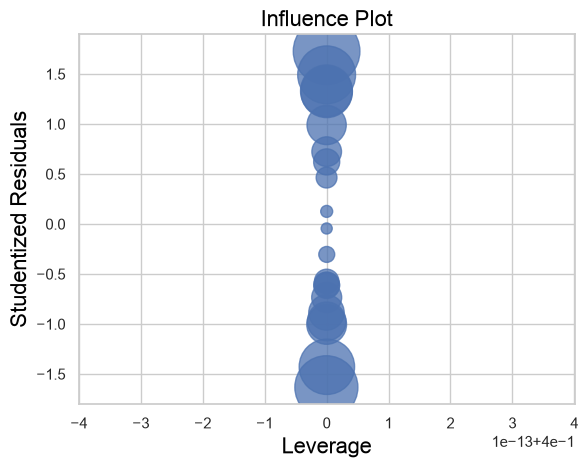

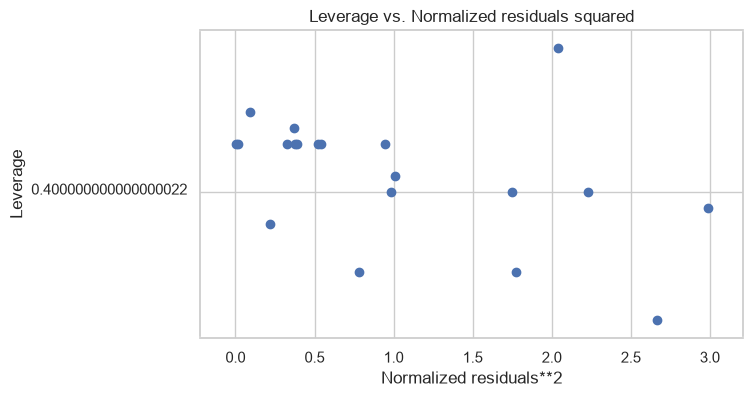

In [7]:
# Regression diagnostics mirroring the lecture content
residuals = model_power_run.resid
fitted = model_power_run.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, residuals, color="black", alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

influence = OLSInfluence(model_power_run)
fig = influence.plot_influence(figsize=(8, 6))
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sm.graphics.plot_leverage_resid2(model_power_run, ax=ax)
plt.show()


In [8]:
# Formal tests from the lecture: normality of residuals, equal variances across power levels, heteroscedasticity, autocorrelation
s_w, s_p = stats.shapiro(residuals)
levene_stat, levene_p = stats.levene(
    *[group["rate"].to_numpy(dtype=float) for _, group in etch_rate.groupby("Power", observed=True)]
)
bartlett_stat, bartlett_p = stats.bartlett(
    *[group["rate"].to_numpy(dtype=float) for _, group in etch_rate.groupby("Power", observed=True)]
)

bp_stat, bp_p, _, _ = het_breuschpagan(residuals, model_power_run.model.exog)
dw_stat = sm.stats.durbin_watson(residuals)

print(f"Shapiro-Wilk (residuals) W = {s_w:.4f}, p-value: {s_p:.3f}")
print(f"Levene (Brown-Forsythe) F = {levene_stat:.4f}, p-value: {levene_p:.3f}")
print(f"Bartlett K^2 = {bartlett_stat:.4f}, p-value: {bartlett_p:.3f}")
print(f"Breusch-Pagan p:     {bp_p:.3f}")
print(f"Durbin-Watson stat:  {dw_stat:.3f}")


Shapiro-Wilk (residuals) W = 0.9465, p-value: 0.317
Levene (Brown-Forsythe) F = 0.1959, p-value: 0.898
Bartlett K^2 = 0.4335, p-value: 0.933
Breusch-Pagan p:     0.038
Durbin-Watson stat:  2.854


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   160    180     36.2 0.0294   3.1456  69.2544   True
   160    200     74.2    0.0  41.1456 107.2544   True
   160    220    155.8    0.0 122.7456 188.8544   True
   180    200     38.0 0.0216   4.9456  71.0544   True
   180    220    119.6    0.0  86.5456 152.6544   True
   200    220     81.6    0.0  48.5456 114.6544   True
------------------------------------------------------


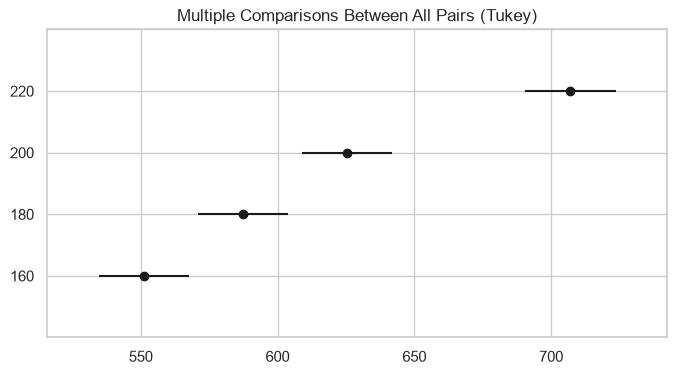

In [9]:
# Tukey HSD multiple comparisons (as demonstrated in the lecture)
tukey = pairwise_tukeyhsd(endog=etch_rate["rate"], groups=etch_rate["Power"], alpha=0.05)
print(tukey)
fig = tukey.plot_simultaneous(figsize=(8, 4))
plt.show()


In [10]:
# Fisher's LSD for the Power-only model (the lecture uses MSE = 333.7 with 16 error df, LSD = 24.49)
means = etch_rate.groupby("Power", observed=True)["rate"].mean()
counts = etch_rate.groupby("Power", observed=True)["rate"].count()
mse = anova_power.loc["Residual", "sum_sq"] / anova_power.loc["Residual", "df"]
df_error = anova_power.loc["Residual", "df"]

alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df_error)
lsd = t_crit * np.sqrt(2 * mse / counts.iloc[0])          # balanced design: all n_i equal
print(f"MSE = {mse:.1f}, error df = {df_error:.0f}, t = {t_crit:.3f}, LSD (alpha = {alpha}) = {lsd:.2f}")
print("Group means (Angstrom/min):"); print(means)

# all pairwise comparisons: |difference| > LSD means the two means differ
rows = []
levels = list(means.index)
for i in range(len(levels)):
    for j in range(i + 1, len(levels)):
        diff = means.iloc[j] - means.iloc[i]
        rows.append({"pair": f"{levels[j]} - {levels[i]}", "difference": diff, "|diff| > LSD": abs(diff) > lsd})
display(pd.DataFrame(rows))

MSE = 333.7, error df = 16, t = 2.120, LSD (alpha = 0.05) = 24.49
Group means (Angstrom/min):
Power
160    551.2
180    587.4
200    625.4
220    707.0
Name: rate, dtype: float64


,pair,difference,|diff| > LSD
0,180 - 160,36.2,True
1,200 - 160,74.2,True
2,220 - 160,155.8,True
3,200 - 180,38.0,True
4,220 - 180,119.6,True
5,220 - 200,81.6,True


,n per group,Phi^2,power
0,4,4.500,0.606
1,5,5.625,0.805
2,6,6.750,0.915
3,7,7.875,0.967
4,8,9.000,0.988
5,9,10.125,0.996
6,10,11.250,0.999


Cohen's f = 1.061; replicates per level for power 0.9: 6 (exact 5.81)


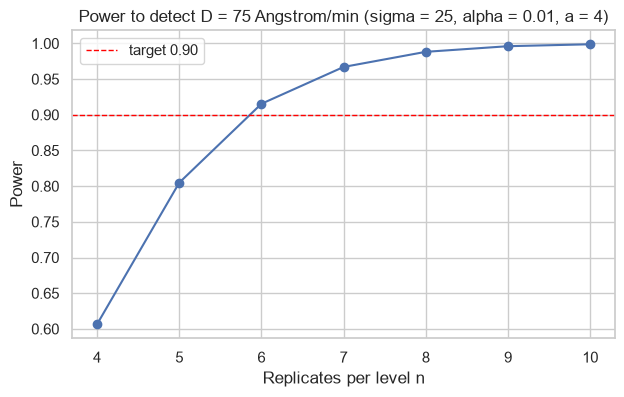

In [11]:
# Sample size: power of the one-way ANOVA F-test for n replicates per level (lecture: D = 75, sigma = 25, alpha = 0.01)
power_analysis = FTestAnovaPower()
alpha = 0.01
sigma = 25          # pilot estimate of the standard deviation
max_diff = 75       # we want to detect two means at least D = 75 Angstrom/min apart
k = 4               # number of levels

# Least favourable configuration: two means D apart, the rest at the overall mean ->
# sum (mu_i - mu)^2 = D^2 / 2, Cohen's f = sqrt(sum (mu_i - mu)^2 / k) / sigma, Phi^2 = n * D^2 / (2 * k * sigma^2)
cohen_f = (max_diff / sigma) * np.sqrt(1 / (2 * k))

sample_sizes = np.arange(4, 11)
power_values = [power_analysis.power(effect_size=cohen_f, nobs=n * k, alpha=alpha, k_groups=k) for n in sample_sizes]
power_df = pd.DataFrame({"n per group": sample_sizes, "Phi^2": sample_sizes * max_diff**2 / (2 * k * sigma**2), "power": power_values})
display(power_df.round(3))

n_needed = power_analysis.solve_power(effect_size=cohen_f, alpha=alpha, power=0.9, k_groups=k) / k
print(f"Cohen's f = {cohen_f:.3f}; replicates per level for power 0.9: {np.ceil(n_needed):.0f} (exact {n_needed:.2f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sample_sizes, power_values, marker="o")
ax.set_xlabel("Replicates per level n"); ax.set_ylabel("Power")
ax.set_title("Power to detect D = 75 Angstrom/min (sigma = 25, alpha = 0.01, a = 4)")
ax.axhline(0.9, color="red", linestyle="--", linewidth=1, label="target 0.90")
ax.legend(); plt.show()

## Assignment

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition), Chapter 3: **3.7, 3.8, 3.9, 3.10, 3.18 and 3.19**. Start in class and finish at home.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; for comparisons of means say which procedure you use and why; check the assumptions with residual plots; end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex02_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 11 October 2026** (the next lecture is on 12 October).


### Problem 3.7: Portland cement tensile strength
The tensile strength of Portland cement is being studied. Four different mixing techniques can be used economically; four replicates per technique were collected in a completely randomized design (strength in lb/in$^2$).


In [12]:
# Data for Problem 3.7
ex03_7 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_7.csv",
    sep=";"
)
ex03_7 = ex03_7.assign(Technique=ex03_7["Technique"].astype("category"))
cement = ex03_7.rename(columns={"Tensile_Strength": "strength"})
cement.head()


,Technique,strength
0,1,3129
1,1,3000
2,1,2865
3,1,2890
4,2,3200


**Question 1.** Construct graphical displays that compare the mean tensile strengths for the four mixing techniques.

,count,mean,std
Technique,,,
1,4,2971.00,120.557040
2,4,3156.25,135.976407
3,4,2933.75,108.272419
4,4,2666.25,80.970674


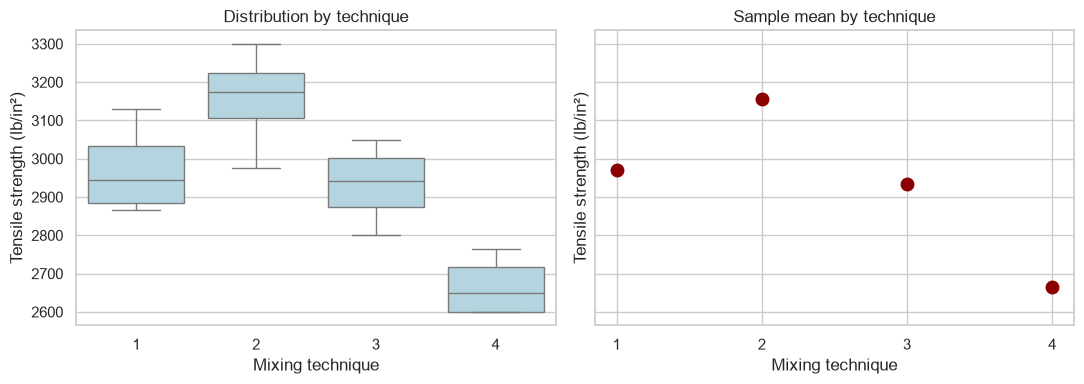

In [13]:
# Compare the four distributions and mark their sample means.
cement_means = cement.groupby("Technique", observed=True)["strength"].mean()
display(cement.groupby("Technique", observed=True)["strength"].agg(["count", "mean", "std"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.boxplot(data=cement, x="Technique", y="strength", color="lightblue", ax=axes[0])
axes[0].set(xlabel="Mixing technique", ylabel="Tensile strength (lb/in²)",
            title="Distribution by technique")
axes[1].plot(range(len(cement_means)), cement_means, color="darkred", marker="o",
             linestyle="none", markersize=9)
axes[1].set_xticks(range(len(cement_means)), labels=cement_means.index)
axes[1].set(xlabel="Mixing technique", ylabel="Tensile strength (lb/in²)",
            title="Sample mean by technique")
plt.tight_layout()
plt.show()

Technique 2 has the largest sample mean (3156.25 lb/in²), followed by 1 (2971.00), 3 (2933.75), and 4 (2666.25). The boxes show within-technique variation as well as the differences between means.

**Question 2.** Test at alpha = 0.05 whether mixing technique affects tensile strength.

In [14]:
# One-way fixed-effects ANOVA: H0: mu1 = mu2 = mu3 = mu4;
# H1: at least one technique has a different mean tensile strength.
alpha_37 = 0.05
model_37 = ols("strength ~ C(Technique)", data=cement).fit()
anova_37 = anova_lm(model_37, typ=2)
display(anova_37)

f_37 = anova_37.loc["C(Technique)", "F"]
p_37 = anova_37.loc["C(Technique)", "PR(>F)"]
print(f"F(3, 12) = {f_37:.3f}, p = {p_37:.6f}")
print("Reject H0: mixing technique affects mean tensile strength."
      if p_37 < alpha_37 else "Do not reject H0: insufficient evidence of a technique effect.")

,sum_sq,df,F,PR(>F)
C(Technique),489740.1875,3.0,12.728107,0.000489
Residual,153908.2500,12.0,NaN,NaN


F(3, 12) = 12.728, p = 0.000489
Reject H0: mixing technique affects mean tensile strength.


At $\alpha=0.05$, the ANOVA gives $F(3,12)=12.728$ and $p=0.000489$. We reject $H_0$: mean tensile strength depends on the mixing technique.

**Question 3.** Use Fisher's LSD method with alpha = 0.05 to make pairwise comparisons between techniques.

In [15]:
# Fisher's protected LSD: use the pooled ANOVA error, after the significant F-test.
from itertools import combinations

mse_37 = anova_37.loc["Residual", "sum_sq"] / anova_37.loc["Residual", "df"]
df_error_37 = int(anova_37.loc["Residual", "df"])
counts_37 = cement.groupby("Technique", observed=True)["strength"].count()

rows_37 = []
for i, j in combinations(cement_means.index, 2):
    difference = cement_means.loc[i] - cement_means.loc[j]
    lsd = stats.t.ppf(1 - alpha_37 / 2, df_error_37) * np.sqrt(
        mse_37 * (1 / counts_37.loc[i] + 1 / counts_37.loc[j]))
    rows_37.append({"comparison": f"{i} - {j}", "mean difference": difference,
                    "LSD": lsd, "significant at 0.05": abs(difference) > lsd})

print(f"MSE = {mse_37:.2f}, error df = {df_error_37}")
display(pd.DataFrame(rows_37).round(2))

MSE = 12825.69, error df = 12


,comparison,mean difference,LSD,significant at 0.05
0,1 - 2,-185.25,174.48,True
1,1 - 3,37.25,174.48,False
2,1 - 4,304.75,174.48,True
3,2 - 3,222.50,174.48,True
4,2 - 4,490.00,174.48,True
5,3 - 4,267.50,174.48,True


The LSD is 174.48 lb/in² for every pair (four observations per technique). All pairs differ significantly except techniques 1 and 3. Fisher's LSD uses the pooled ANOVA error and the significant overall $F$ test; it does not control the familywise error rate as strictly as Tukey's method.

**Question 4.** Construct a normal probability plot of the residuals. Does the normality assumption appear reasonable?

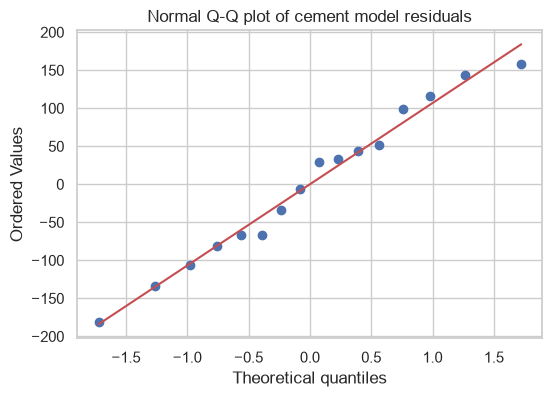

Shapiro-Wilk W = 0.970, p = 0.846


In [16]:
# Check the ANOVA residuals against the normal distribution.
fig, ax = plt.subplots(figsize=(6, 4))
stats.probplot(model_37.resid, dist="norm", plot=ax)
ax.set_title("Normal Q-Q plot of cement model residuals")
plt.show()

shapiro_37 = stats.shapiro(model_37.resid)
print(f"Shapiro-Wilk W = {shapiro_37.statistic:.3f}, p = {shapiro_37.pvalue:.3f}")

The Q-Q points are reasonably close to a straight line. Shapiro-Wilk gives $p=0.846$, so there is no evidence against normal residuals, though the sample is small.

**Question 5.** Plot the residuals versus the fitted tensile strength and comment.

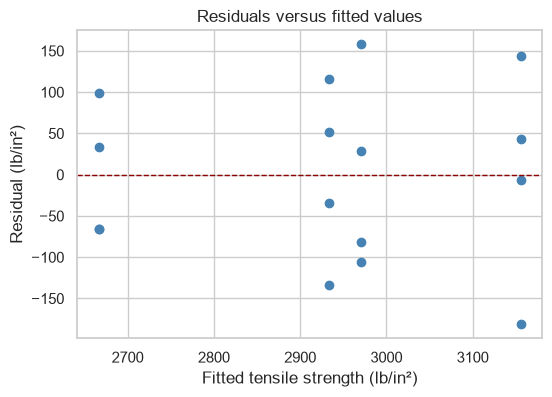

Brown-Forsythe (equal spread): statistic = 0.183, p = 0.906


In [17]:
# Look for changing spread or a curved pattern across fitted means.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(model_37.fittedvalues, model_37.resid, color="steelblue")
ax.axhline(0, color="darkred", linestyle="--", linewidth=1)
ax.set(xlabel="Fitted tensile strength (lb/in²)", ylabel="Residual (lb/in²)",
       title="Residuals versus fitted values")
plt.show()

groups_37 = [g["strength"].to_numpy() for _, g in cement.groupby("Technique", observed=True)]
levene_37 = stats.levene(*groups_37, center="median")
print(f"Brown-Forsythe (equal spread): statistic = {levene_37.statistic:.3f}, "
      f"p = {levene_37.pvalue:.3f}")

The residuals show no clear curve or funnel shape. Their spreads are broadly similar across fitted means; the Brown-Forsythe test gives $p=0.906$. These checks do not reveal a serious violation of the ANOVA assumptions. The experiment's randomization supports independence.

**Question 6.** Prepare a scatter plot of the raw observations to aid interpretation.

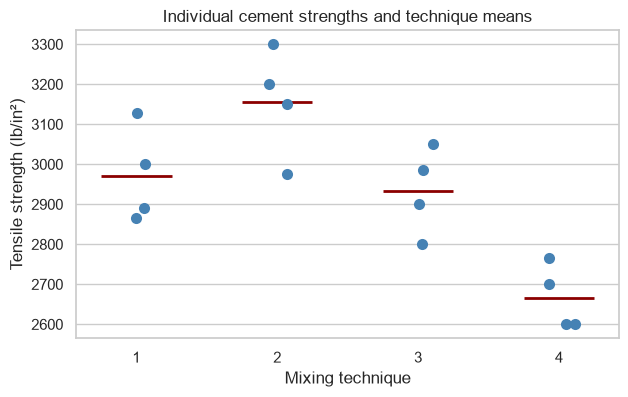

In [18]:
# Each point is one observation; horizontal marks show the technique means.
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=cement, x="Technique", y="strength", jitter=0.12,
              color="steelblue", size=8, ax=ax)
for x_pos, mean in enumerate(cement_means):
    ax.hlines(mean, x_pos - 0.25, x_pos + 0.25, colors="darkred", linewidth=2)
ax.set(xlabel="Mixing technique", ylabel="Tensile strength (lb/in²)",
       title="Individual cement strengths and technique means")
plt.show()

The raw observations reinforce the ANOVA result: technique 4 tends to give the lowest strengths, technique 2 the highest, and techniques 1 and 3 overlap substantially. For the highest mean tensile strength among these four techniques, technique 2 is the best candidate.


### Problems 3.8 and 3.9: follow-up comparisons for the cement data
We revisit the Portland cement experiment to explore multiple comparisons and confidence intervals.


**Question 1.** Rework the pairwise comparisons using Tukey's test with alpha = 0.05. Do the conclusions match the graphical procedure and Fisher's LSD?

In [19]:
# Tukey HSD tests H0: mu_i = mu_j against H1: mu_i != mu_j for all pairs.
# It controls the familywise error rate at 0.05 across the six comparisons.
tukey_37 = pairwise_tukeyhsd(cement['strength'], cement['Technique'], alpha=0.05)
print(tukey_37)
q_37 = stats.studentized_range.ppf(0.95, 4, df_error_37)
hsd_37 = q_37 * np.sqrt(mse_37 / counts_37.iloc[0])
print(f"Studentized-range critical value = {q_37:.3f}; HSD = {hsd_37:.2f}")
# Standardized absolute differences are the studentized-range test statistics.
for i, j in combinations(cement_means.index, 2):
    q = abs(cement_means.loc[i] - cement_means.loc[j]) / np.sqrt(mse_37 / 4)
    print(f"{i} vs {j}: q = {q:.3f}")

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2 meandiff p-adj    lower     upper   reject
--------------------------------------------------------
     1      2   185.25 0.1494  -52.5003  423.0003  False
     1      3   -37.25 0.9653 -275.0003  200.5003  False
     1      4  -304.75 0.0116 -542.5003  -66.9997   True
     2      3   -222.5 0.0693 -460.2503   15.2503  False
     2      4   -490.0 0.0003 -727.7503 -252.2497   True
     3      4   -267.5 0.0262 -505.2503  -29.7497   True
--------------------------------------------------------
Studentized-range critical value = 4.199; HSD = 237.75
1 vs 2: q = 3.272
1 vs 3: q = 0.658
1 vs 4: q = 5.382
2 vs 3: q = 3.929
2 vs 4: q = 8.653
3 vs 4: q = 4.724


Tukey's HSD is 237.75 lb/in². Only pairs 1–4, 2–4 and 3–4 are significant (adjusted p-values 0.0116, 0.0003 and 0.0262). This agrees with the broad graphical pattern that technique 4 is weakest, but Fisher's LSD also declares 1–2 and 2–3 significant. Technique 2 has the largest observed mean, but Tukey's test does not establish that it exceeds techniques 1 and 3.


**Question 2.** Explain the difference between Tukey's procedure and Fisher's LSD.


Fisher's protected LSD first requires a significant overall ANOVA, then uses two-sided pooled-error t tests for individual pairs. Each comparison uses a 5% significance level, but with four treatments this does not generally control the familywise error rate at 5%. Tukey's procedure uses the studentized-range distribution and controls the probability of at least one false rejection across all pairwise comparisons at 5%, under the ANOVA assumptions. Its simultaneous confidence intervals are wider, so it detects fewer differences here. LSD is used where explicitly requested; Tukey is preferable when all pairs form one family of comparisons.

**Question 3.** Find 95 percent confidence intervals for each technique mean and for the difference between techniques 1 and 3. How do these intervals aid interpretation?

In [20]:
# Individual (not simultaneous) t intervals using the pooled ANOVA error.
t_37 = stats.t.ppf(0.975, df_error_37)
se_means_37 = np.sqrt(mse_37 / counts_37)
ci_means_37 = pd.DataFrame({'mean': cement_means,
                           '95% lower': cement_means - t_37 * se_means_37,
                           '95% upper': cement_means + t_37 * se_means_37})
display(ci_means_37.round(2))
diff_13 = cement_means.loc[1] - cement_means.loc[3]
se_13 = np.sqrt(mse_37 * (1 / counts_37.loc[1] + 1 / counts_37.loc[3]))
ci_13 = diff_13 + np.array([-1, 1]) * t_37 * se_13
print(f"mu1 - mu3 estimate = {diff_13:.2f}; 95% CI = ({ci_13[0]:.2f}, {ci_13[1]:.2f})")

,mean,95% lower,95% upper
Technique,,,
1,2971.00,2847.62,3094.38
2,3156.25,3032.87,3279.63
3,2933.75,2810.37,3057.13
4,2666.25,2542.87,2789.63


mu1 - mu3 estimate = 37.25; 95% CI = (-137.23, 211.73)


The individual 95% intervals are (2847.62, 3094.38), (3032.87, 3279.63), (2810.37, 3057.13) and (2542.87, 2789.63) lb/in² for techniques 1–4. The interval for $\mu_1-\mu_3$ is (−137.23, 211.73) lb/in²: zero is plausible, so a difference is not established. These intervals quantify uncertainty and plausible effect sizes; overlap of separate mean intervals is not itself a pairwise significance test. The residual checks in Problem 3.7 also apply to these follow-up analyses.


### Problem 3.10: cotton content and fibre strength
A product developer is investigating the tensile strength of a new synthetic fibre. The percentage of cotton in the blend is varied over five levels (15, 20, 25, 30, 35 %) with five replicates per level, run in random order.


In [21]:
# Data for Problem 3.10
ex03_10 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_10.csv",
    sep=";"
).rename(columns={"Cotton_Weight ": "Cotton_Weight", "Observations": "strength"})
ex03_10 = ex03_10.assign(Cotton_Weight=ex03_10["Cotton_Weight"].astype("category"))
ex03_10.head()


,Cotton_Weight,strength
0,15,7
1,20,12
2,25,14
3,30,19
4,35,7


**Question 1.** Test at alpha = 0.05 whether cotton content affects mean fibre strength.

In [22]:
# H0: mu15 = mu20 = mu25 = mu30 = mu35; H1: not all means are equal.
model_310 = ols('strength ~ C(Cotton_Weight)', data=ex03_10).fit()
anova_310 = anova_lm(model_310, typ=2)
display(anova_310)
print(f"F({int(model_310.df_model)}, {int(model_310.df_resid)}) = "
      f"{model_310.fvalue:.4f}, p = {model_310.f_pvalue:.8f}")
print('Reject H0 at 0.05.' if model_310.f_pvalue < 0.05 else 'Do not reject H0.')
display(ex03_10.groupby('Cotton_Weight', observed=True)['strength'].agg(['count', 'mean', 'std']))

,sum_sq,df,F,PR(>F)
C(Cotton_Weight),475.76,4.0,14.756824,0.000009
Residual,161.20,20.0,NaN,NaN


F(4, 20) = 14.7568, p = 0.00000913
Reject H0 at 0.05.


,count,mean,std
Cotton_Weight,,,
15,5,9.8,3.346640
20,5,15.4,3.130495
25,5,17.6,2.073644
30,5,21.6,2.607681
35,5,10.8,2.863564


The ANOVA gives $F(4,20)=14.757$, $p=9.13\times10^{-6}$, so cotton content affects mean fibre strength. The sample means at 15, 20, 25, 30 and 35% cotton are 9.8, 15.4, 17.6, 21.6 and 10.8, respectively.

**Question 2.** Use Fisher's LSD (alpha = 0.05) to compare the mean strengths across cotton levels.

In [23]:
def fisher_lsd(data, factor, response, model, alpha=0.05):
    """Two-sided pairwise t tests with the fitted ANOVA's pooled error."""
    grouped = data.groupby(factor, observed=True)[response]
    means, counts = grouped.mean(), grouped.count()
    critical = stats.t.ppf(1 - alpha / 2, model.df_resid)
    rows = []
    for i, j in combinations(means.index, 2):
        difference = means.loc[i] - means.loc[j]
        se = np.sqrt(model.mse_resid * (1 / counts.loc[i] + 1 / counts.loc[j]))
        t_value = difference / se
        p_value = 2 * stats.t.sf(abs(t_value), model.df_resid)
        rows.append({'pair': f'{i} - {j}', 'difference': difference,
                     't': t_value, 'df': int(model.df_resid), 'p (unadjusted)': p_value,
                     'LSD': critical * se, 'reject H0': p_value < alpha})
    return pd.DataFrame(rows)

# Each H0: mu_i = mu_j versus H1: mu_i != mu_j.
# Protected LSD is used as requested, following the significant overall F test.
lsd_310 = fisher_lsd(ex03_10, 'Cotton_Weight', 'strength', model_310)
display(lsd_310.round(5))

,pair,difference,t,df,p (unadjusted),LSD,reject H0
0,15 - 20,-5.6,-3.11882,20,0.00541,3.74545,True
1,15 - 25,-7.8,-4.34407,20,0.00031,3.74545,True
2,15 - 30,-11.8,-6.57180,20,0.00000,3.74545,True
3,15 - 35,-1.0,-0.55693,20,0.58375,3.74545,False
4,20 - 25,-2.2,-1.22525,20,0.23471,3.74545,False
5,20 - 30,-6.2,-3.45298,20,0.00251,3.74545,True
6,20 - 35,4.6,2.56189,20,0.01859,3.74545,True
7,25 - 30,-4.0,-2.22773,20,0.03754,3.74545,True
8,25 - 35,6.8,3.78714,20,0.00116,3.74545,True
9,30 - 35,10.8,6.01487,20,0.00001,3.74545,True


With pooled $MS_E=8.06$ and 20 error degrees of freedom, LSD = 3.745. All pairs differ at the individual 5% level except 15–35% and 20–25%. In particular, 30% cotton has a significantly higher mean than every other tested level under Fisher's LSD. These are unadjusted pairwise conclusions, not simultaneous 95% guarantees.

**Question 3.** Analyse residuals and comment on model adequacy.

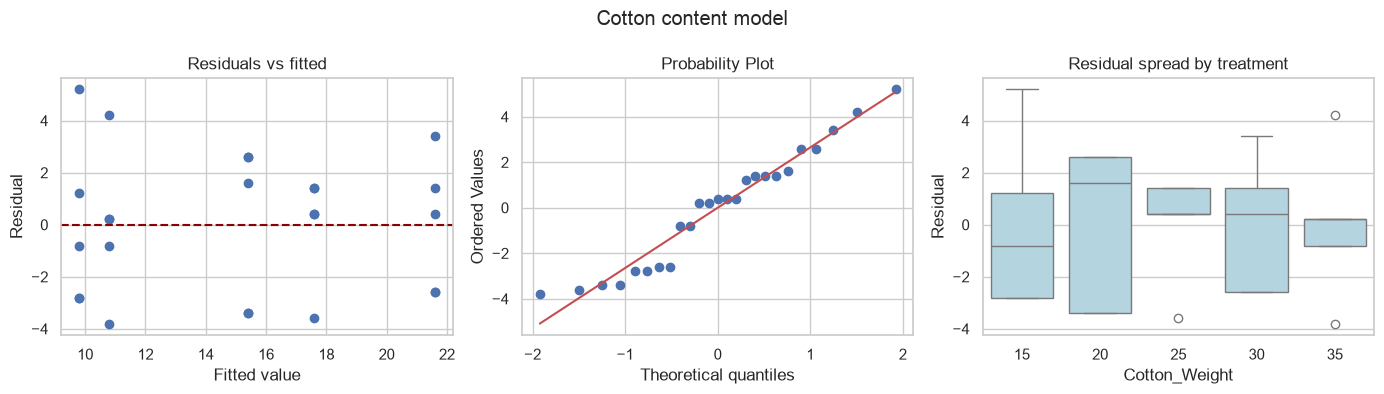

Shapiro-Wilk: statistic = 0.9439, p = 0.1818; do not reject H0
Brown-Forsythe: statistic = 0.3179, p = 0.8626; do not reject H0


In [24]:
def check_oneway(model, data, factor, response, title):
    """Residual diagnostics; row order is not assumed to be run order."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].scatter(model.fittedvalues, model.resid)
    axes[0].axhline(0, color='darkred', linestyle='--')
    axes[0].set(xlabel='Fitted value', ylabel='Residual', title='Residuals vs fitted')
    stats.probplot(model.resid, dist='norm', plot=axes[1])
    sns.boxplot(x=data[factor], y=model.resid, ax=axes[2], color='lightblue')
    axes[2].set(xlabel=factor, ylabel='Residual', title='Residual spread by treatment')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    # Shapiro H0: errors are normal; H1: departure from normality.
    # Brown-Forsythe H0: equal group variances; H1: some variances differ.
    sw = stats.shapiro(model.resid)
    groups = [g[response].to_numpy() for _, g in data.groupby(factor, observed=True)]
    bf = stats.levene(*groups, center='median')
    for name, result in [('Shapiro-Wilk', sw), ('Brown-Forsythe', bf)]:
        print(f'{name}: statistic = {result.statistic:.4f}, p = {result.pvalue:.4f}; '
              + ('reject H0' if result.pvalue < 0.05 else 'do not reject H0'))

check_oneway(model_310, ex03_10, 'Cotton_Weight', 'strength', 'Cotton content model')

Shapiro–Wilk gives $W=0.944$, $p=0.182$ and Brown–Forsythe gives $F=0.318$, $p=0.863$; neither null hypothesis is rejected. The plots show no pronounced funnel and are reasonably compatible with normal errors. Randomized runs support independence; the CSV row order is not a documented run sequence, so it cannot verify independence. With only five observations per level, these checks have limited power. Among the tested blends, 30% cotton gives the greatest estimated strength; the decline at 35% cautions against assuming a monotonic relationship.

### Problems 3.18 and 3.19: coating of colour picture tubes

A manufacturer of television sets is interested in the effect on tube conductivity of four different types of coating for colour picture tubes.
A completely randomized experiment is conducted and the following conductivity data are obtained:

| Coating type | Conductivity |
|---|---|
| 1 | 143, 141, 150, 146 |
| 2 | 152, 149, 137, 143 |
| 3 | 134, 136, 132, 127 |
| 4 | 129, 127, 132, 129 |

In [25]:
# Data for Problems 3.18 and 3.19
ex03_18 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_18.csv",
    sep=";"
)
ex03_18.columns = [c.strip() for c in ex03_18.columns]
ex03_18 = ex03_18.assign(Type=ex03_18["Type"].astype("category"))
ex03_18.head()

,Type,Conductivity
0,1,143
1,1,141
2,1,150
3,1,146
4,2,152


**Question 1.** Is there a difference in conductivity due to coating type? Use alpha = 0.05.

In [26]:
# H0: mu1 = mu2 = mu3 = mu4; H1: at least one coating mean differs.
model_318 = ols('Conductivity ~ C(Type)', data=ex03_18).fit()
anova_318 = anova_lm(model_318, typ=2)
display(anova_318)
print(f'F(3, 12) = {model_318.fvalue:.4f}, p = {model_318.f_pvalue:.6f}')
print('Reject H0 at 0.05.' if model_318.f_pvalue < 0.05 else 'Do not reject H0.')

,sum_sq,df,F,PR(>F)
C(Type),844.6875,3.0,14.301587,0.000288
Residual,236.2500,12.0,NaN,NaN


F(3, 12) = 14.3016, p = 0.000288
Reject H0 at 0.05.


Since $F(3,12)=14.302$, $p=0.000288$, we reject equality of the four means: coating type affects mean conductivity.

**Question 2.** Estimate the overall mean and the treatment effects.

In [27]:
# Sum-to-zero parameterization: y_ij = mu + tau_i + error_ij.
means_318 = ex03_18.groupby('Type', observed=True)['Conductivity'].mean()
counts_318 = ex03_18.groupby('Type', observed=True)['Conductivity'].count()
grand_318 = ex03_18['Conductivity'].mean()
effects_318 = means_318 - grand_318
print(f'Estimated overall mean = {grand_318:.4f}')
display(pd.DataFrame({'mean': means_318, 'treatment effect': effects_318}))
print(f'Sum of treatment effects = {effects_318.sum():.6f}')

Estimated overall mean = 137.9375


,mean,treatment effect
Type,,
1,145.00,7.0625
2,145.25,7.3125
3,132.25,-5.6875
4,129.25,-8.6875


Sum of treatment effects = 0.000000


The estimated overall mean is 137.3125. Under the sum-to-zero constraint, treatment effects for coatings 1–4 are 7.6875, 7.9375, −5.0625 and −8.0625. Coatings 1 and 2 are above the overall mean, while 3 and 4 are below it.

**Question 3.** Compute a 95% confidence interval for the mean of coating type 4 and a 99% confidence interval for the mean difference between coatings 1 and 4.

In [28]:
mse_318, df_318 = model_318.mse_resid, int(model_318.df_resid)
ci4 = means_318.loc[4] + np.array([-1, 1]) * stats.t.ppf(0.975, df_318) * np.sqrt(
    mse_318 / counts_318.loc[4])
diff14 = means_318.loc[1] - means_318.loc[4]
ci14 = diff14 + np.array([-1, 1]) * stats.t.ppf(0.995, df_318) * np.sqrt(
    mse_318 * (1 / counts_318.loc[1] + 1 / counts_318.loc[4]))
print(f'MSE = {mse_318:.4f}, error df = {df_318}')
print(f'mu4: estimate = {means_318.loc[4]:.2f}; 95% CI = ({ci4[0]:.2f}, {ci4[1]:.2f})')
print(f'mu1 - mu4: estimate = {diff14:.2f}; 99% CI = ({ci14[0]:.2f}, {ci14[1]:.2f})')

MSE = 19.6875, error df = 12
mu4: estimate = 129.25; 95% CI = (124.42, 134.08)
mu1 - mu4: estimate = 15.75; 99% CI = (6.17, 25.33)


The individual 95% confidence interval for coating 4 is (124.42, 134.08). The 99% interval for $\mu_1-\mu_4$ is (6.17, 25.33), suggesting substantially higher conductivity with coating 1 than with coating 4.

**Question 4.** Test all pairs of means using the Fisher LSD method with alpha = 0.05.

In [29]:
# Each H0: mu_i = mu_j versus H1: mu_i != mu_j, at alpha = 0.05.
# Use protected Fisher LSD with the pooled one-way ANOVA error.
lsd_318 = fisher_lsd(ex03_18, 'Type', 'Conductivity', model_318)
display(lsd_318.round(5))

,pair,difference,t,df,p (unadjusted),LSD,reject H0
0,1 - 2,-0.25,-0.07968,12,0.93780,6.83597,False
1,1 - 3,12.75,4.06378,12,0.00157,6.83597,True
2,1 - 4,15.75,5.01996,12,0.00030,6.83597,True
3,2 - 3,13.00,4.14346,12,0.00136,6.83597,True
4,2 - 4,16.00,5.09964,12,0.00026,6.83597,True
5,3 - 4,3.00,0.95618,12,0.35785,6.83597,False


LSD = 6.836, using $MS_E=19.6875$ and 12 error degrees of freedom. Pairs 1–3, 1–4, 2–3 and 2–4 differ significantly; 1–2 and 3–4 do not. Thus the results distinguish a higher-conductivity pair (1, 2) from a lower-conductivity pair (3, 4), without proving equality within either pair.

**Question 5.** Use the graphical method from Section 3.5.3 of Montgomery (plot the means with a scaled $t$ distribution) to compare the means. Which coating type produces the highest conductivity?

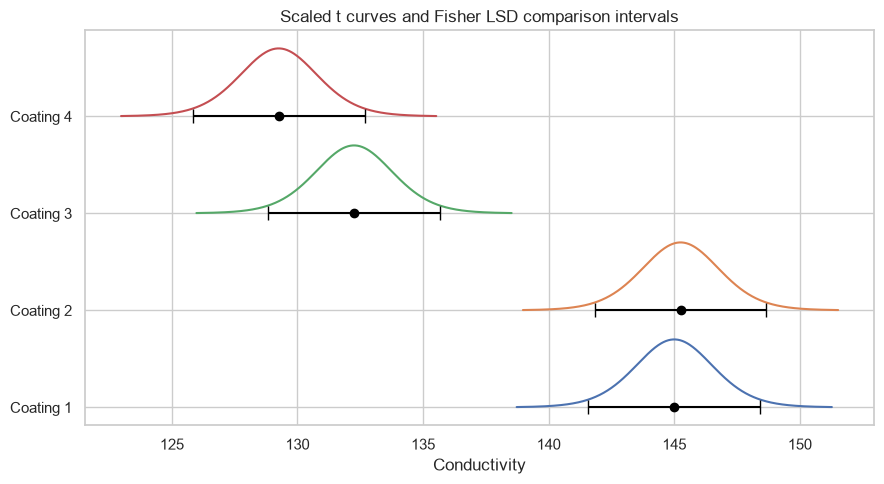

Comparison interval half-width = LSD/2 = 3.418


In [30]:
# For equal n, use t curves with scale sqrt(MSE/(2*n)).
# Their central 95% half-width is LSD/2: two intervals fail to overlap
# exactly when the pairwise mean difference exceeds Fisher's LSD.
scale_318 = np.sqrt(mse_318 / (2 * counts_318.iloc[0]))
half_lsd_318 = stats.t.ppf(0.975, df_318) * scale_318
fig, ax = plt.subplots(figsize=(9, 5))
for row, (coating, mean) in enumerate(means_318.items()):
    x = np.linspace(mean - 4 * scale_318, mean + 4 * scale_318, 400)
    density = stats.t.pdf((x - mean) / scale_318, df_318)
    ax.plot(x, row + 0.7 * density / density.max(), label=f'Coating {coating}')
    ax.errorbar(mean, row, xerr=half_lsd_318, fmt='o', color='black', capsize=5)
ax.set(yticks=range(4), yticklabels=[f'Coating {i}' for i in means_318.index],
       xlabel='Conductivity', title='Scaled t curves and Fisher LSD comparison intervals')
plt.tight_layout()
plt.show()
print(f'Comparison interval half-width = LSD/2 = {half_lsd_318:.3f}')

The non-overlapping comparison intervals separate coatings 1 and 2 from coatings 3 and 4, agreeing with Fisher's LSD. These are graphical comparison intervals of half-width LSD/2, **not** individual 95% confidence intervals for the means. Coating 2 has the highest sample mean (145.25), but its difference from coating 1 (145.00) is not significant.

**Question 6.** Assuming coating type 4 is currently in use and conductivity should be minimised, what is your recommendation?

Keep coating 4 if conductivity is to be minimized: it has the lowest sample mean (129.25), and coatings 1 and 2 have significantly higher means. Coating 3 has a mean of 132.25 and is not significantly different from coating 4, so the experiment provides no evidence that switching to 3 would improve conductivity. A nonsignificant difference does not prove equivalence; cost or other performance criteria could motivate further investigation.

**Question 7.** Analyse the residuals and comment on model adequacy.

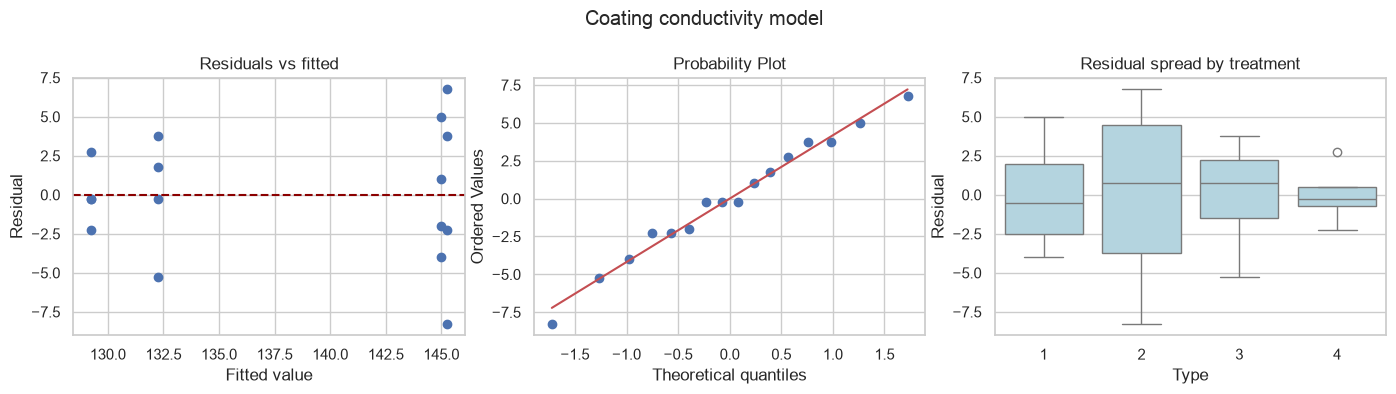

Shapiro-Wilk: statistic = 0.9842, p = 0.9882; do not reject H0
Brown-Forsythe: statistic = 2.2068, p = 0.1401; do not reject H0


In [31]:
check_oneway(model_318, ex03_18, 'Type', 'Conductivity', 'Coating conductivity model')

The Q-Q plot is approximately linear (Shapiro–Wilk $W=0.984$, $p=0.988$). Coating 2 has visibly greater spread and coating 4 less, but Brown–Forsythe gives $F=2.207$, $p=0.140$, so equal variances are not rejected at 5%. Four observations per coating give weak power for detecting variance differences, so some caution is appropriate. The completely randomized design supports independence; the data are grouped by coating rather than recorded in run order. Overall, the model is a reasonable working approximation: coatings 1 and 2 yield higher conductivity, and retaining coating 4 is reasonable when minimizing conductivity.